In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'    # has to be set before keras is imported

import numpy as np
import keras

from keras.layers import Conv2D, Resizing, Add
from custom_layers import Conv2Dx2Block, DownscaleBlock, UpscaleBlock
from model_base import ModelBase, plot_history, visualize_result
import cv2
import optuna
from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 5]

In [2]:
# model adapted for use with optuna
class OptimizableModel(ModelBase):
    def __init__(self, filters=32, filters_last=128, kernel_size=3, kernel_size_add=2, learning_rate=0.002, gradient_accumulation_steps=4):
        self.filters = filters
        self.filters_last = filters_last
        self.kernel_size = kernel_size
        self.kernel_size_add = kernel_size_add
        super().__init__(f'opt_{filters}_{filters_last}_{kernel_size}_{learning_rate}_{gradient_accumulation_steps}', batch_size=16)

    def create(self, inputs):
        filters = [self.filters, self.filters * 2, self.filters * 4]
        x1, p = DownscaleBlock(filters[0], kernel_size=self.kernel_size+self.kernel_size_add)(inputs)
        x2, p = DownscaleBlock(filters[1], kernel_size=self.kernel_size)(p)
        
        x = Conv2Dx2Block(filters[2])(p)
        
        x = UpscaleBlock(filters[1], concat=True, kernel_size=self.kernel_size)(x, x2)
        x = UpscaleBlock(filters[0], concat=True, kernel_size=self.kernel_size+self.kernel_size_add)(x, x1)

        x = UpscaleBlock(self.filters_last)(x)

        residual = Conv2D(3, kernel_size=1, padding="same", activation=None, kernel_initializer=keras.initializers.RandomNormal(stddev=1e-3), bias_initializer="zeros")(x)
        base = Resizing(128, 128, interpolation="bicubic")(inputs)
        return Add()([base, residual])

# pruning callback for trials displaying poor validation loss
class PruningCallback(keras.callbacks.Callback):
    def __init__(self, trial):
        super().__init__()
        self.trial = trial

    def on_epoch_end(self, epoch, logs=None):
        self.trial.report(logs["val_loss"], step=epoch)
        if self.trial.should_prune():
            raise optuna.TrialPruned()

def objective(trial):
    """Objective function that controls the quality of the different runs.
    
    Args:
        trial (optuna.trial.Trial) Wrapper that controls the launching and the
            hyper-parameters of the different runs.
            
    Returns:
        (float) The quality metric of the current run.
        
    """
    # set the seed before every trial
    keras.utils.set_random_seed(1234)

    learning_rate = trial.suggest_float("learning_rate", 0.0002, 0.002, log=True)
    gradient_accumulation_steps = trial.suggest_int("gradient_accumulation_steps", 1, 4)
    model = OptimizableModel(
        filters=trial.suggest_categorical("filters", [32, 64]),
        filters_last=trial.suggest_categorical("filters_last", [32, 64, 128]),
        kernel_size=trial.suggest_categorical("kernel_size", [3, 5]),
        kernel_size_add=trial.suggest_categorical("kernel_size_add", [0, 2]),
        learning_rate=learning_rate,
        gradient_accumulation_steps=gradient_accumulation_steps
    )
    model.fit(
        epochs=20,
        learning_rate=learning_rate,
        gradient_accumulation_steps=gradient_accumulation_steps,
        pruning_callback=PruningCallback(trial)
    )
    # return model's performance on validation set
    return model.evaluate()

In [3]:
# Create Optuna study
study = optuna.create_study(direction="minimize", pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5))

# Launch hyper-parameter search
study.optimize(objective, n_trials=20)

print('Number of finished trials:', len(study.trials))

# Show detailed info about finished trials
study.trials_dataframe()

[I 2026-11-16 01:25:10,945] A new study created in memory with name: no-name-4d75daf3-3ef0-46e4-bd09-7dfd3507e2fd


Epoch 1/20
596/596 - 110s - 185ms/step - loss: 0.0229 - val_loss: 0.0215 - learning_rate: 6.5366e-04
Epoch 2/20
596/596 - 110s - 184ms/step - loss: 0.0229 - val_loss: 0.0215 - learning_rate: 6.5366e-04
Epoch 3/20
596/596 - 110s - 184ms/step - loss: 0.0229 - val_loss: 0.0215 - learning_rate: 6.5366e-04
Epoch 4/20
596/596 - 110s - 184ms/step - loss: 0.0229 - val_loss: 0.0215 - learning_rate: 6.5366e-04
Epoch 5/20
596/596 - 110s - 185ms/step - loss: 0.0228 - val_loss: 0.0215 - learning_rate: 6.5366e-04
Epoch 6/20
596/596 - 110s - 184ms/step - loss: 0.0229 - val_loss: 0.0215 - learning_rate: 6.5366e-04
Epoch 7/20
596/596 - 110s - 185ms/step - loss: 0.0228 - val_loss: 0.0215 - learning_rate: 6.5366e-04
Epoch 8/20
596/596 - 110s - 185ms/step - loss: 0.0227 - val_loss: 0.0212 - learning_rate: 6.5366e-04
Epoch 9/20
596/596 - 117s - 196ms/step - loss: 0.0221 - val_loss: 0.0206 - learning_rate: 6.5366e-04
Epoch 10/20
596/596 - 121s - 204ms/step - loss: 0.0215 - val_loss: 0.0198 - learning_rate: 

[I 2026-11-16 02:04:08,061] Trial 0 finished with value: 0.019854754209518433 and parameters: {'learning_rate': 0.0006536570069180902, 'gradient_accumulation_steps': 3, 'filters': 64, 'filters_last': 32, 'kernel_size': 5, 'kernel_size_add': 2}. Best is trial 0 with value: 0.019854754209518433.


Epoch 1/20
596/596 - 139s - 234ms/step - loss: 0.0229 - val_loss: 0.0215 - learning_rate: 2.6160e-04
Epoch 2/20
596/596 - 139s - 234ms/step - loss: 0.0226 - val_loss: 0.0691 - learning_rate: 2.6160e-04
Epoch 3/20
596/596 - 139s - 234ms/step - loss: 0.0217 - val_loss: 0.0199 - learning_rate: 2.6160e-04
Epoch 4/20
596/596 - 139s - 234ms/step - loss: 0.0212 - val_loss: 0.0197 - learning_rate: 2.6160e-04
Epoch 5/20
596/596 - 139s - 234ms/step - loss: 0.0209 - val_loss: 0.0192 - learning_rate: 2.6160e-04
Epoch 6/20
596/596 - 139s - 233ms/step - loss: 0.0208 - val_loss: 0.0194 - learning_rate: 2.6160e-04
Epoch 7/20
596/596 - 139s - 234ms/step - loss: 0.0207 - val_loss: 0.0192 - learning_rate: 2.6160e-04
Epoch 8/20
596/596 - 139s - 234ms/step - loss: 0.0205 - val_loss: 0.0191 - learning_rate: 2.6160e-04
Epoch 9/20
596/596 - 139s - 234ms/step - loss: 0.0204 - val_loss: 0.0189 - learning_rate: 2.6160e-04
Epoch 10/20
596/596 - 139s - 233ms/step - loss: 0.0203 - val_loss: 0.0187 - learning_rate: 

[I 2026-11-16 02:50:40,071] Trial 1 finished with value: 0.019576089456677437 and parameters: {'learning_rate': 0.000261596087609413, 'gradient_accumulation_steps': 4, 'filters': 64, 'filters_last': 64, 'kernel_size': 5, 'kernel_size_add': 2}. Best is trial 1 with value: 0.019576089456677437.


Epoch 1/20


... (37 outputs left out)

Epoch 1/20
596/596 - 81s - 137ms/step - loss: 0.0220 - val_loss: 0.0200 - learning_rate: 2.1403e-04
Epoch 2/20
596/596 - 82s - 137ms/step - loss: 0.0210 - val_loss: 0.0199 - learning_rate: 2.1403e-04
Epoch 3/20
596/596 - 80s - 134ms/step - loss: 0.0207 - val_loss: 0.0189 - learning_rate: 2.1403e-04
Epoch 4/20
596/596 - 80s - 134ms/step - loss: 0.0206 - val_loss: 0.0190 - learning_rate: 2.1403e-04
Epoch 5/20
596/596 - 80s - 134ms/step - loss: 0.0204 - val_loss: 0.0187 - learning_rate: 2.1403e-04
Epoch 6/20
596/596 - 80s - 134ms/step - loss: 0.0203 - val_loss: 0.0187 - learning_rate: 2.1403e-04
Epoch 7/20
596/596 - 80s - 134ms/step - loss: 0.0201 - val_loss: 0.0185 - learning_rate: 2.1403e-04
Epoch 8/20
596/596 - 86s - 144ms/step - loss: 0.0200 - val_loss: 0.0185 - learning_rate: 2.1403e-04
Epoch 9/20
596/596 - 80s - 134ms/step - loss: 0.0199 - val_loss: 0.0184 - learning_rate: 2.1403e-04
Epoch 10/20
596/596 - 80s - 134ms/step - loss: 0.0199 - val_loss: 0.0181 - learning_rate: 2.1403e-04

[I 2026-11-16 12:43:13,891] Trial 19 finished with value: 0.01883513852953911 and parameters: {'learning_rate': 0.00021403291531556194, 'gradient_accumulation_steps': 1, 'filters': 64, 'filters_last': 64, 'kernel_size': 3, 'kernel_size_add': 0}. Best is trial 19 with value: 0.01883513852953911.


Number of finished trials: 20


,number,value,datetime_start,datetime_complete,duration,params_filters,params_filters_last,params_gradient_accumulation_steps,params_kernel_size,params_kernel_size_add,params_learning_rate,system_attrs_tpe:relative_params:0,state
0,0,0.019855,2026-11-16 01:25:10.947276,2026-11-16 02:04:08.061436,0 days 00:38:57.114160,64,32,3,5,2,0.000654,NaN,COMPLETE
1,1,0.019576,2026-11-16 02:04:08.062006,2026-11-16 02:50:40.071584,0 days 00:46:32.009578,64,64,4,5,2,0.000262,NaN,COMPLETE
2,2,0.019782,2026-11-16 02:50:40.072128,2026-11-16 03:31:49.905468,0 days 00:41:09.833340,32,128,3,5,0,0.000856,NaN,COMPLETE
3,3,0.019382,2026-11-16 03:31:49.906005,2026-11-16 04:28:03.808578,0 days 00:56:13.902573,64,128,2,3,2,0.000691,NaN,COMPLETE
4,4,0.019406,2026-11-16 04:28:03.809111,2026-11-16 05:19:04.378761,0 days 00:51:00.569650,64,128,4,3,0,0.000668,NaN,COMPLETE
5,5,0.019696,2026-11-16 05:19:04.379287,2026-11-16 05:45:38.445163,0 days 00:26:34.065876,32,64,1,5,0,0.000342,NaN,COMPLETE
6,6,0.018682,2026-11-16 05:45:38.445716,2026-11-16 05:57:02.983102,0 days 00:11:24.537386,32,64,3,3,0,0.000661,NaN,PRUNED
7,7,0.019266,2026-11-16 05:57:02.983623,2026-11-16 06:04:17.621856,0 days 00:07:14.638233,32,32,4,3,2,0.000727,NaN,PRUNED
8,8,0.020888,2026-11-16 06:04:17.622338,2026-11-16 06:10:22.428970,0 days 00:06:04.806632,32,32,3,5,0,0.001434,NaN,PRUNED
9,9,0.029751,2026-11-16 06:10:22.429457,2026-11-16 06:18:37.328306,0 days 00:08:14.898849,64,64,1,3,0,0.001917,NaN,PRUNED


(Text(0.5, 0, 'trial'), Text(0, 0.5, 'metric'))

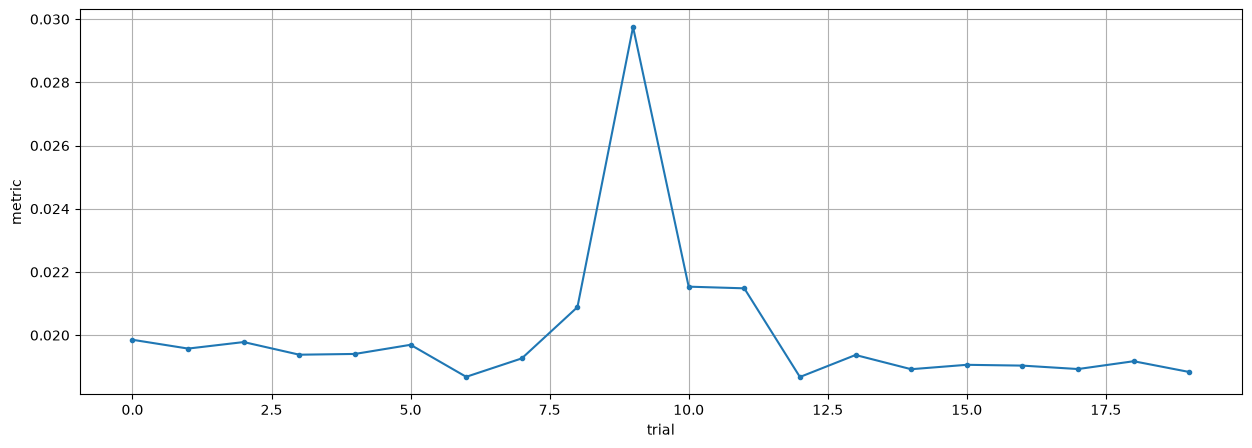

In [4]:
metrics = [trial.value for trial in study.trials]
plt.plot(metrics, '.-'), plt.grid(True)
plt.xlabel('trial'), plt.ylabel('metric')

In [5]:
# Show best trial
trial = study.best_trial
print('Best trial:', trial.number, '\n')
print('  Metric:', trial.value)
print('  Params:')
for key, value in trial.params.items():
    print('\t', key.ljust(13), ':', value)

Best trial: 19 

  Metric: 0.01883513852953911
  Params:
	 learning_rate : 0.00021403291531556194
	 gradient_accumulation_steps : 1
	 filters       : 64
	 filters_last  : 64
	 kernel_size   : 3
	 kernel_size_add : 0


In [6]:
# Show overall stats
mu = np.mean([trial.value for trial in study.trials])
std = np.std([trial.value for trial in study.trials])

print('Avg metric:', np.mean(mu))
print('Std metric:', np.mean(std))

Avg metric: 0.0200656620785594
Std metric: 0.002366172775357935


(Text(0.5, 0, 'Importance'), None)

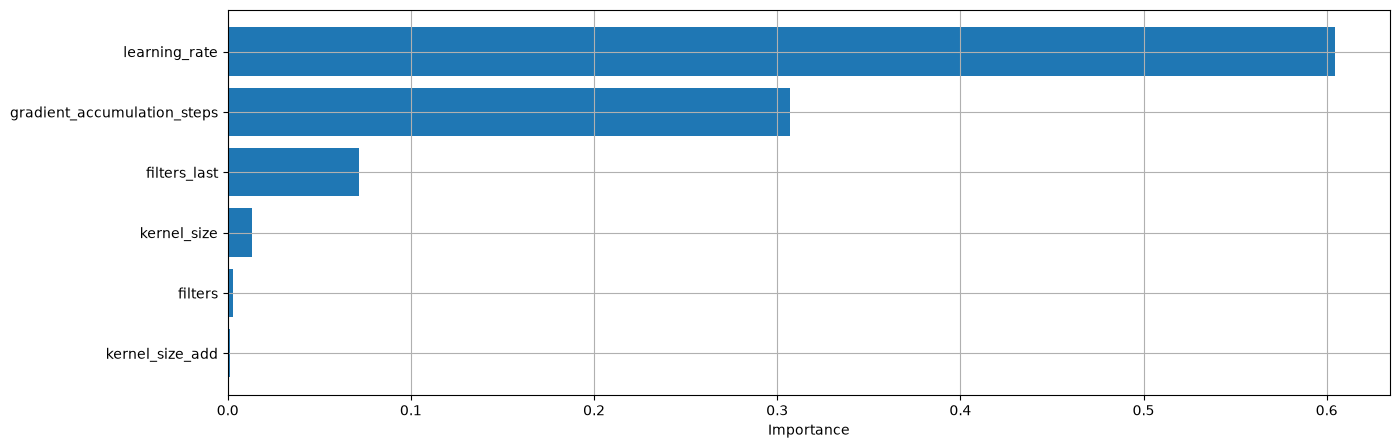

In [7]:
importances = optuna.importance.get_param_importances(study)
plt.barh(list(importances)[::-1], list(importances.values())[::-1])
plt.xlabel('Importance'), plt.grid(True)

In [8]:
for t in study.trials:
    print(t)

FrozenTrial(number=0, state=<TrialState.COMPLETE: 1>, values=[0.019854754209518433], datetime_start=datetime.datetime(2026, 11, 16, 1, 25, 10, 947276), datetime_complete=datetime.datetime(2026, 11, 16, 2, 4, 8, 61436), params={'learning_rate': 0.0006536570069180902, 'gradient_accumulation_steps': 3, 'filters': 64, 'filters_last': 32, 'kernel_size': 5, 'kernel_size_add': 2}, user_attrs={}, system_attrs={}, intermediate_values={0: 0.021490735933184624, 1: 0.021506644785404205, 2: 0.021522732451558113, 3: 0.021523714065551758, 4: 0.02150212600827217, 5: 0.021538957953453064, 6: 0.021451139822602272, 7: 0.02119765616953373, 8: 0.020558351650834084, 9: 0.01976473443210125, 10: 0.019778648391366005, 11: 0.019199639558792114, 12: 0.019049275666475296, 13: 0.019442347809672356, 14: 0.0190279558300972, 15: 0.018922990188002586, 16: 0.018833989277482033, 17: 0.018874896690249443, 18: 0.018675366416573524, 19: 0.018726782873272896}, distributions={'learning_rate': FloatDistribution(high=0.002, lo